<center><h1>bagai_sanchit_HW8</h1></center>

Name: Sanchit Bagai
<br>
Github Username: baked-potatoes
<br>
USC ID: 1033382623

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
)
from scipy.special import softmax
from joblib import Parallel, delayed

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
cols = ["id", "diagnosis"] + [f"f{i}" for i in range(1, 31)]
df = pd.read_csv("../data/wdbc.data", header=None, names=cols)

y = (df["diagnosis"] == "M").astype(int).values
X = df.drop(columns=["id", "diagnosis"]).values

print("Shape:", X.shape)
print("Class counts:\n", pd.Series(y).value_counts().rename({0: "Benign", 1: "Malignant"}))
# df.head()

Shape: (569, 30)
Class counts:
 Benign       357
Malignant    212
Name: count, dtype: int64


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

Average scores over 30 runs:
            Train    Test
Accuracy   0.9860  0.9652
Precision  0.9918  0.9706
Recall     0.9706  0.9349
F1         0.9810  0.9518
AUC        0.9972  0.9918

Best C (run 0): 0.0379269019073225
Train confusion matrix:
 [[284   1]
 [  5 165]]
Test confusion matrix:
 [[68  4]
 [ 3 39]]


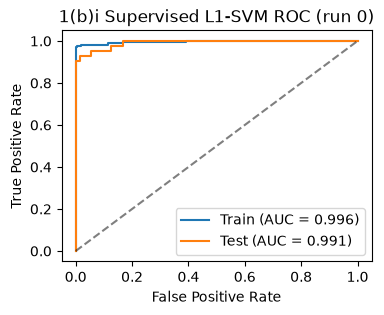

In [3]:
M = 30
C_grid = {"C": np.logspace(-3, 3, 20)}

def get_metrics(y_true, y_pred, y_score):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred),
        recall_score(y_true, y_pred),
        f1_score(y_true, y_pred),
        roc_auc_score(y_true, y_score),
    ]

metric_names = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
train_metrics, test_metrics = [], []
saved = {}

for run in range(M):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=run
    )

    scaler = StandardScaler().fit(X_tr)
    X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

    svm = GridSearchCV(
        LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=42),
        C_grid, cv=5, scoring="accuracy"
    )
    svm.fit(X_tr_s, y_tr)

    tr_pred, te_pred = svm.predict(X_tr_s), svm.predict(X_te_s)
    tr_score, te_score = svm.decision_function(X_tr_s), svm.decision_function(X_te_s)

    train_metrics.append(get_metrics(y_tr, tr_pred, tr_score))
    test_metrics.append(get_metrics(y_te, te_pred, te_score))

    if run == 0:
        saved = dict(y_tr=y_tr, y_te=y_te, tr_pred=tr_pred, te_pred=te_pred,
                     tr_score=tr_score, te_score=te_score, best_C=svm.best_params_["C"])

summary = pd.DataFrame(
    {"Train": np.mean(train_metrics, axis=0), "Test": np.mean(test_metrics, axis=0)},
    index=metric_names
)
print("Average scores over", M, "runs:")
print(summary.round(4))

print("\nBest C (run 0):", saved["best_C"])
print("Train confusion matrix:\n", confusion_matrix(saved["y_tr"], saved["tr_pred"]))
print("Test confusion matrix:\n", confusion_matrix(saved["y_te"], saved["te_pred"]))

plt.figure(figsize=(4, 3))
for name, yt, sc in [("Train", saved["y_tr"], saved["tr_score"]),
                     ("Test", saved["y_te"], saved["te_score"])]:
    fpr, tpr, _ = roc_curve(yt, sc)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yt, sc):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("1(b)i Supervised L1-SVM ROC (run 0)")
plt.legend()
plt.show()

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0
)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

X_lab, X_unlab, y_lab, y_unlab_true = train_test_split(
    X_tr_s, y_tr, test_size=0.5, stratify=y_tr, random_state=0
)

svm_A = GridSearchCV(
    LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=42),
    C_grid, cv=5, scoring="accuracy"
)
svm_A.fit(X_lab, y_lab)

print("Labeled:", X_lab.shape[0], "| Unlabeled:", X_unlab.shape[0])
print("Labeled class counts:", np.bincount(y_lab))
print("Best C:", svm_A.best_params_["C"])
print("Labeled CV accuracy:", round(svm_A.best_score_, 4))
print("Test accuracy (labeled-only SVM):", round(svm_A.score(X_te_s, y_te), 4))

Labeled: 227 | Unlabeled: 228
Labeled class counts: [142  85]
Best C: 0.1623776739188721
Labeled CV accuracy: 0.9693
Test accuracy (labeled-only SVM): 0.9737


##### (B)

Self-training: average scores over 30 runs
            Train    Test
Accuracy   0.9776  0.9649
Precision  0.9828  0.9723
Recall     0.9569  0.9325
F1         0.9696  0.9513
AUC        0.9945  0.9929

Train confusion matrix (run 0):
 [[284   1]
 [  8 162]]
Test confusion matrix (run 0):
 [[69  3]
 [ 3 39]]


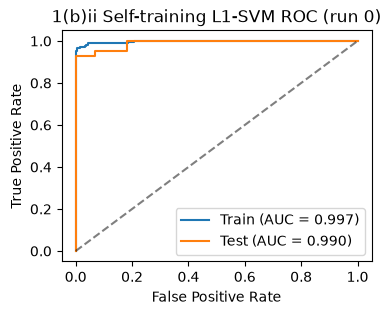

In [5]:
def fit_svm(X_l, y_l):
    min_class = np.bincount(y_l, minlength=2).min()
    cv = min(5, min_class) if min_class >= 2 else None
    if cv is None:
        return LinearSVC(penalty="l1", dual=False, C=1.0, max_iter=10000, random_state=42).fit(X_l, y_l)
    gs = GridSearchCV(
        LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=42),
        C_grid, cv=cv, scoring="accuracy"
    )
    return gs.fit(X_l, y_l).best_estimator_

def self_train(X_lab, y_lab, X_unlab, retune_every=1):
    X_l, y_l = X_lab.copy(), y_lab.copy()
    X_u = X_unlab.copy()
    model = fit_svm(X_l, y_l)
    step = 0
    while len(X_u) > 0:
        scores = model.decision_function(X_u)
        idx = np.argmax(np.abs(scores))
        pseudo = int(scores[idx] > 0)
        X_l = np.vstack([X_l, X_u[idx:idx + 1]])
        y_l = np.append(y_l, pseudo)
        X_u = np.delete(X_u, idx, axis=0)
        step += 1
        if step % retune_every == 0 or len(X_u) == 0:
            model = fit_svm(X_l, y_l)
        else:
            model = LinearSVC(penalty="l1", dual=False, C=model.C, max_iter=10000, random_state=42).fit(X_l, y_l)
    return model

def semi_run(run):
    warnings.simplefilter("ignore")
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=run
    )
    scaler = StandardScaler().fit(X_tr)
    X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

    X_lab, X_unlab, y_lab, _ = train_test_split(
        X_tr_s, y_tr, test_size=0.5, stratify=y_tr, random_state=run
    )

    model = self_train(X_lab, y_lab, X_unlab)

    tr_pred, te_pred = model.predict(X_tr_s), model.predict(X_te_s)
    tr_score, te_score = model.decision_function(X_tr_s), model.decision_function(X_te_s)

    saved = dict(y_tr=y_tr, y_te=y_te, tr_pred=tr_pred, te_pred=te_pred,
                 tr_score=tr_score, te_score=te_score) if run == 0 else None
    return get_metrics(y_tr, tr_pred, tr_score), get_metrics(y_te, te_pred, te_score), saved

results = Parallel(n_jobs=-1)(delayed(semi_run)(run) for run in range(M))

semi_train_metrics = [r[0] for r in results]
semi_test_metrics = [r[1] for r in results]
semi_saved = results[0][2]

semi_summary = pd.DataFrame(
    {"Train": np.mean(semi_train_metrics, axis=0), "Test": np.mean(semi_test_metrics, axis=0)},
    index=metric_names
)
print("Self-training: average scores over", M, "runs")
print(semi_summary.round(4))

print("\nTrain confusion matrix (run 0):\n", confusion_matrix(semi_saved["y_tr"], semi_saved["tr_pred"]))
print("Test confusion matrix (run 0):\n", confusion_matrix(semi_saved["y_te"], semi_saved["te_pred"]))

plt.figure(figsize=(4, 3))
for name, yt, sc in [("Train", semi_saved["y_tr"], semi_saved["tr_score"]),
                     ("Test", semi_saved["y_te"], semi_saved["te_score"])]:
    fpr, tpr, _ = roc_curve(yt, sc)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yt, sc):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("1(b)ii Self-training L1-SVM ROC (run 0)")
plt.legend()
plt.show()

#### (iii) Unsupervised Learning

##### (A)

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0
)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

n_restarts = 50
single_runs = [
    KMeans(n_clusters=2, init="random", n_init=1, random_state=s).fit(X_tr_s)
    for s in range(n_restarts)
]
inertias = np.array([km.inertia_ for km in single_runs])

best = single_runs[int(np.argmin(inertias))]
print(f"Inertia over {n_restarts} random initializations:")
print(f"  min  = {inertias.min():.4f}")
print(f"  max  = {inertias.max():.4f}")
print(f"  std  = {inertias.std():.6f}")
print(f"  # runs reaching the minimum (within 1e-6): {np.sum(np.isclose(inertias, inertias.min(), atol=1e-6))}/{n_restarts}")

agree = [max(np.mean(km.labels_ == best.labels_), np.mean(km.labels_ != best.labels_))
         for km in single_runs]
print(f"  min partition agreement with best run: {min(agree):.4f}")

kmeans = KMeans(n_clusters=2, init="random", n_init=50, random_state=0).fit(X_tr_s)
print(f"\nKMeans(n_init=50) inertia: {kmeans.inertia_:.4f}") 

Inertia over 50 random initializations:
  min  = 9216.6769
  max  = 9216.6769
  std  = 0.000000
  # runs reaching the minimum (within 1e-6): 50/50
  min partition agreement with best run: 1.0000

KMeans(n_init=50) inertia: 9216.6769


K means can get stuck in local minima so it was run 50 times with random initialization. All the runs reached the same minima and the same partition, so the solution is likely to be the global minima.

##### (B)

K-means (train): average scores over 30 runs
            Train
Accuracy   0.9103
Precision  0.9239
Recall     0.8284
F1         0.8734
AUC        0.9749

Cluster labels (run 0): [0 1]
Train confusion matrix (run 0):
 [[277   8]
 [ 33 137]]


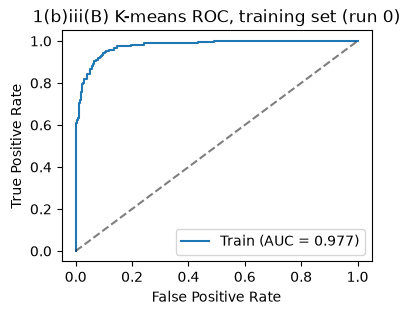

In [7]:
def kmeans_classifier(X_tr_s, y_tr, n_closest=30, seed=0):
    km = KMeans(n_clusters=2, init="random", n_init=20, random_state=seed).fit(X_tr_s)
    dists = km.transform(X_tr_s)

    cluster_label = np.zeros(2, dtype=int)
    for k in range(2):
        closest = np.argsort(dists[:, k])[:n_closest]
        cluster_label[k] = int(y_tr[closest].mean() > 0.5)
    return km, cluster_label

def kmeans_scores(km, cluster_label, X_s):
    probs = softmax(-km.transform(X_s), axis=1)
    return probs[:, cluster_label == 1].sum(axis=1)

km_train_metrics = []
km_saved = {}

for run in range(M):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=run
    )
    scaler = StandardScaler().fit(X_tr)
    X_tr_s = scaler.transform(X_tr)

    km, cluster_label = kmeans_classifier(X_tr_s, y_tr, seed=run)

    tr_pred = cluster_label[km.labels_]
    tr_score = kmeans_scores(km, cluster_label, X_tr_s)

    km_train_metrics.append(get_metrics(y_tr, tr_pred, tr_score))

    if run == 0:
        km_saved = dict(y_tr=y_tr, tr_pred=tr_pred, tr_score=tr_score,
                        cluster_label=cluster_label)

km_summary = pd.DataFrame(
    {"Train": np.mean(km_train_metrics, axis=0)}, index=metric_names
)
print("K-means (train): average scores over", M, "runs")
print(km_summary.round(4))

print("\nCluster labels (run 0):", km_saved["cluster_label"])
print("Train confusion matrix (run 0):\n",
      confusion_matrix(km_saved["y_tr"], km_saved["tr_pred"]))

fpr, tpr, _ = roc_curve(km_saved["y_tr"], km_saved["tr_score"])
plt.figure(figsize=(4, 3))
plt.plot(fpr, tpr, label=f"Train (AUC = {roc_auc_score(km_saved['y_tr'], km_saved['tr_score']):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("1(b)iii(B) K-means ROC, training set (run 0)")
plt.legend()
plt.show()

##### (C)

K-means: average scores over 30 runs
            Train    Test
Accuracy   0.9103  0.9053
Precision  0.9239  0.9096
Recall     0.8284  0.8262
F1         0.8734  0.8647
AUC        0.9749  0.9719

Test confusion matrix (run 0):
 [[65  7]
 [ 7 35]]


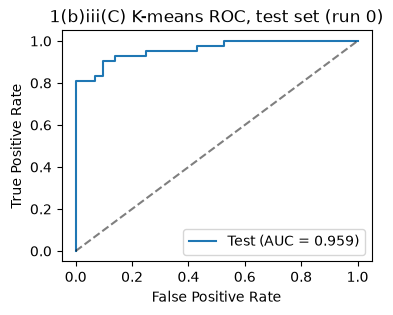

In [8]:
km_test_metrics = []
km_test_saved = {}

for run in range(M):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=run
    )
    scaler = StandardScaler().fit(X_tr)
    X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

    km, cluster_label = kmeans_classifier(X_tr_s, y_tr, seed=run)

    te_pred = cluster_label[km.predict(X_te_s)]
    te_score = kmeans_scores(km, cluster_label, X_te_s)

    km_test_metrics.append(get_metrics(y_te, te_pred, te_score))

    if run == 0:
        km_test_saved = dict(y_te=y_te, te_pred=te_pred, te_score=te_score)

km_summary["Test"] = np.mean(km_test_metrics, axis=0)
print("K-means: average scores over", M, "runs")
print(km_summary.round(4))

print("\nTest confusion matrix (run 0):\n",
      confusion_matrix(km_test_saved["y_te"], km_test_saved["te_pred"]))

fpr, tpr, _ = roc_curve(km_test_saved["y_te"], km_test_saved["te_score"])
plt.figure(figsize=(4, 3))
plt.plot(fpr, tpr, label=f"Test (AUC = {roc_auc_score(km_test_saved['y_te'], km_test_saved['te_score']):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("1(b)iii(C) K-means ROC, test set (run 0)")
plt.legend()
plt.show()

#### (iv) Spectral Clustering

gamma=1 cluster sizes: [567   2] -> degenerate; searching for a better gamma

Spectral clustering: average scores over 30 runs
            Train    Test
Accuracy   0.9090  0.9064
Precision  0.9235  0.9128
Recall     0.8251  0.8270
F1         0.8714  0.8664
AUC        0.9716  0.9696

Run 0 -> chosen gamma: 0.0001 | cluster sizes: [380 189] | cluster labels: [0 1]
Train confusion matrix (run 0):
 [[277   8]
 [ 32 138]]
Test confusion matrix (run 0):
 [[66  6]
 [ 5 37]]


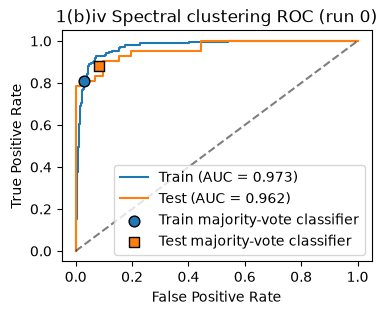

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
scaler = StandardScaler().fit(X_tr)
X_all0 = np.vstack([scaler.transform(X_tr), scaler.transform(X_te)])
lab_g1 = SpectralClustering(n_clusters=2, affinity="rbf", gamma=1, random_state=0).fit_predict(X_all0)
print("gamma=1 cluster sizes:", np.bincount(lab_g1), "-> degenerate; searching for a better gamma")

gamma_grid = np.logspace(-4, -1, 13)
target_frac = min(y.mean(), 1 - y.mean())

def spectral_run(run, fixed_gamma=None):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=run
    )
    scaler = StandardScaler().fit(X_tr)
    X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
    X_all = np.vstack([X_tr_s, X_te_s])
    n_tr = len(X_tr_s)

    if fixed_gamma is not None:
        gamma = fixed_gamma
        lab = SpectralClustering(n_clusters=2, affinity="rbf", gamma=gamma,
                                 random_state=run).fit_predict(X_all)
    else:
        best = None
        for g in gamma_grid:
            lab = SpectralClustering(n_clusters=2, affinity="rbf", gamma=g,
                                     random_state=run).fit_predict(X_all)
            gap = abs(min(lab.mean(), 1 - lab.mean()) - target_frac)
            if best is None or gap < best[0]:
                best = (gap, g, lab)
        _, gamma, lab = best

    cluster_label = np.array([int(y_tr[lab[:n_tr] == k].mean() > 0.5) for k in range(2)])
    pred = cluster_label[lab]

    K = rbf_kernel(X_all, X_tr_s, gamma=gamma)
    pos = pred[:n_tr] == 1
    if pos.all() or (~pos).all():                       # degenerate: no usable score
        score = np.zeros(len(X_all))
    else:
        score = K[:, pos].mean(axis=1) - K[:, ~pos].mean(axis=1)

    return (y_tr, y_te, pred[:n_tr], pred[n_tr:], score[:n_tr], score[n_tr:],
            gamma, np.bincount(lab, minlength=2), cluster_label)

sp_train_metrics, sp_test_metrics = [], []
sp_saved = {}

for run in range(M):
    y_tr, y_te, tr_pred, te_pred, tr_score, te_score, gamma, cl_sizes, cl = spectral_run(run)
    sp_train_metrics.append(get_metrics(y_tr, tr_pred, tr_score))
    sp_test_metrics.append(get_metrics(y_te, te_pred, te_score))
    if run == 0:
        sp_saved = dict(y_tr=y_tr, y_te=y_te, tr_pred=tr_pred, te_pred=te_pred,
                        tr_score=tr_score, te_score=te_score,
                        gamma=gamma, sizes=cl_sizes, cl=cl)

sp_summary = pd.DataFrame(
    {"Train": np.mean(sp_train_metrics, axis=0), "Test": np.mean(sp_test_metrics, axis=0)},
    index=metric_names
)
print("\nSpectral clustering: average scores over", M, "runs")
print(sp_summary.round(4))

print("\nRun 0 -> chosen gamma:", sp_saved["gamma"], "| cluster sizes:", sp_saved["sizes"],
      "| cluster labels:", sp_saved["cl"])
print("Train confusion matrix (run 0):\n", confusion_matrix(sp_saved["y_tr"], sp_saved["tr_pred"]))
print("Test confusion matrix (run 0):\n", confusion_matrix(sp_saved["y_te"], sp_saved["te_pred"]))

plt.figure(figsize=(4, 3))
for name, yt, sc in [("Train", sp_saved["y_tr"], sp_saved["tr_score"]),
                     ("Test", sp_saved["y_te"], sp_saved["te_score"])]:
    fpr, tpr, _ = roc_curve(yt, sc)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yt, sc):.3f})")

for name, yt, pr, mk in [("Train", sp_saved["y_tr"], sp_saved["tr_pred"], "o"),
                         ("Test", sp_saved["y_te"], sp_saved["te_pred"], "s")]:
    tn, fp, fn, tp = confusion_matrix(yt, pr).ravel()
    plt.scatter(fp / (fp + tn), tp / (tp + fn), marker=mk, s=60, edgecolor="k",
                zorder=3, label=f"{name} majority-vote classifier")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("1(b)iv Spectral clustering ROC (run 0)")
plt.legend()
plt.show()

Spectral clustering uses an RBF similarity graph and Laplacian eigenvectors to identify non-convex clusters, but lacks cluster centers and a `predict` method.

Train and test points were clustered together using `fit_predict`, with clusters labeled by majority vote of training points. ROC scores use the difference in mean RBF affinity to predicted positive and negative training points, instead of varying the majority-poll threshold (footnote 3). Gamma was chosen by closest class balance; in run 0, $10^{-4}$ yielded clusters of 380 and 189 versus the original 357 and 212, with no exact match found.

In [10]:
g1_train, g1_test = [], []
for run in range(M):
    r = spectral_run(run, fixed_gamma=1)
    g1_train.append(get_metrics(r[0], r[2], r[4]))
    g1_test.append(get_metrics(r[1], r[3], r[5]))
    if run == 0:
        g1_saved = dict(y_tr=r[0], y_te=r[1], tr_pred=r[2], te_pred=r[3], sizes=r[7])

g1_summary = pd.DataFrame(
    {"Train": np.mean(g1_train, axis=0), "Test": np.mean(g1_test, axis=0)}, index=metric_names
)
cmp_g = pd.concat({"gamma = 1": g1_summary, "best gamma": sp_summary}, axis=1)
print("Spectral clustering, gamma = 1 vs best gamma: average scores over", M, "runs")
print(cmp_g.round(4))

Spectral clustering, gamma = 1 vs best gamma: average scores over 30 runs
          gamma = 1         best gamma        
              Train    Test      Train    Test
Accuracy     0.6300  0.6348     0.9090  0.9064
Precision    1.0000  0.3667     0.9235  0.9128
Recall       0.0096  0.0087     0.8251  0.8270
F1           0.0190  0.0171     0.8714  0.8664
AUC          0.7740  0.7747     0.9716  0.9696


With $\gamma = 1$ the clustering is degenerate (567 vs 2 points in run 0), giving test accuracy 0.6348 and recall 0.0087 against 0.9064 and 0.8270 for the best gamma, which is used for the results above.

#### (v) Compare

Average test scores over 30 runs:

| Method | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Supervised | 0.9652 | 0.9706 | 0.9349 | 0.9518 | 0.9918 |
| Self-training | 0.9649 | 0.9723 | 0.9325 | 0.9513 | 0.9929 |
| K-means | 0.9053 | 0.9096 | 0.8262 | 0.8647 | 0.9719 |
| Spectral | 0.9064 | 0.9128 | 0.8270 | 0.8664 | 0.9696 |

Supervised learning and self-training with half the labels perform almost identically. K-means and spectral clustering are about 6 points lower in accuracy and 10 points lower in recall, since they never use labels while clustering. The ranking is supervised ≈ self-training > spectral ≈ k-means.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [11]:
bank_cols = ["variance", "skewness", "curtosis", "entropy", "class"]
bank = pd.read_csv("../data/data_banknote_authentication.txt", header=None, names=bank_cols)

Xb = bank.drop(columns="class").values
yb = bank["class"].values

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    Xb, yb, test_size=472, random_state=0
)

scaler_b = StandardScaler().fit(Xb_tr)
Xb_tr_s, Xb_te_s = scaler_b.transform(Xb_tr), scaler_b.transform(Xb_te)

print("Total:", Xb.shape, "| Train:", Xb_tr_s.shape, "| Test:", Xb_te_s.shape)
print("Class counts (all):", np.bincount(yb))
print("Class counts (train):", np.bincount(yb_tr), "| (test):", np.bincount(yb_te))
# bank.head()

Total: (1372, 4) | Train: (900, 4) | Test: (472, 4)
Class counts (all): [762 610]
Class counts (train): [500 400] | (test): [262 210]


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [12]:
n_reps = 50
step = 10
sizes = np.arange(10, 901, step)
C_grid_b = {"C": np.logspace(-3, 1, 5)}

def fit_l1_svm(X_l, y_l):
    min_class = np.bincount(y_l, minlength=2).min()
    if min_class < 2:
        return LinearSVC(penalty="l1", dual=False, C=1.0, max_iter=10000, random_state=42).fit(X_l, y_l)
    gs = GridSearchCV(
        LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=42),
        C_grid_b, cv=min(5, min_class), scoring="accuracy"
    )
    return gs.fit(X_l, y_l).best_estimator_

def initial_order(seed):
    rng = np.random.RandomState(seed)
    while True:
        order = rng.permutation(len(Xb_tr_s))
        if len(np.unique(yb_tr[order[:10]])) == 2:
            return order

def passive_run(seed):
    order = initial_order(seed)
    errs = []
    for n in sizes:
        idx = np.sort(order[:n])
        model = fit_l1_svm(Xb_tr_s[idx], yb_tr[idx])
        errs.append(1 - model.score(Xb_te_s, yb_te))
    return errs

passive_errors = np.array(
    Parallel(n_jobs=-1)(delayed(passive_run)(seed) for seed in range(n_reps))
)

print("passive_errors shape:", passive_errors.shape)
print("Mean test error with 10 points :", passive_errors[:, 0].mean().round(4))
print("Mean test error with 100 points:", passive_errors[:, 9].mean().round(4))
print("Mean test error with 900 points:", passive_errors[:, -1].mean().round(4))

passive_errors shape: (50, 90)
Mean test error with 10 points : 0.1308
Mean test error with 100 points: 0.0239
Mean test error with 900 points: 0.0127


#### (ii) Active

In [13]:
def active_run(seed):
    warnings.simplefilter("ignore")
    order = initial_order(seed)
    pool = order[:10]
    remaining = order[10:]
    errs = []
    for n in sizes:
        idx = np.sort(pool)
        model = fit_l1_svm(Xb_tr_s[idx], yb_tr[idx])
        errs.append(1 - model.score(Xb_te_s, yb_te))

        if len(remaining) > 0:
            dist = np.abs(model.decision_function(Xb_tr_s[remaining]))
            closest = np.argsort(dist)[:step]
            pool = np.concatenate([pool, remaining[closest]])
            remaining = np.delete(remaining, closest)
    return errs

active_errors = np.array(
    Parallel(n_jobs=-1)(delayed(active_run)(seed) for seed in range(n_reps))
)

print("active_errors shape:", active_errors.shape)
print("Mean test error with 10 points :", active_errors[:, 0].mean().round(4))
print("Mean test error with 100 points:", active_errors[:, 9].mean().round(4))
print("Mean test error with 900 points:", active_errors[:, -1].mean().round(4))
print("\nPassive vs active, mean error at 10 points (should match):",
      passive_errors[:, 0].mean().round(4), active_errors[:, 0].mean().round(4))

active_errors shape: (50, 90)
Mean test error with 10 points : 0.1308
Mean test error with 100 points: 0.0144
Mean test error with 900 points: 0.0127

Passive vs active, mean error at 10 points (should match): 0.1308 0.1308


### (c) Average the 50 test errors

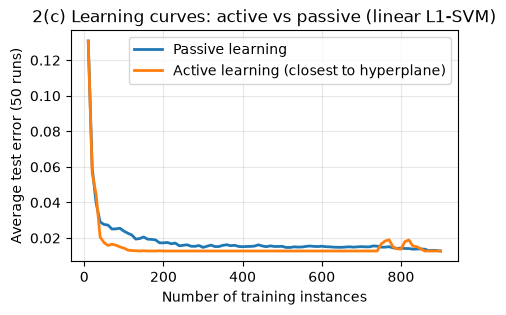

         Passive  Active  Passive - Active
n_train                                   
10        0.1308  0.1308            0.0000
20        0.0594  0.0566            0.0028
50        0.0276  0.0174            0.0102
100       0.0239  0.0144            0.0095
200       0.0173  0.0127            0.0046
300       0.0147  0.0127            0.0020
500       0.0153  0.0127            0.0026
900       0.0127  0.0127            0.0000
First size with mean error <= 0.03: passive = 40, active = 40
First size with mean error <= 0.02: passive = 130, active = 50
First size with mean error <= 0.015: passive = 300, active = 90

At 900 points (same data, should match): 0.0127 0.0127


In [14]:
passive_mean = passive_errors.mean(axis=0)
active_mean = active_errors.mean(axis=0)

plt.figure(figsize=(5, 3))
plt.plot(sizes, passive_mean, label="Passive learning", linewidth=2)
plt.plot(sizes, active_mean, label="Active learning (closest to hyperplane)", linewidth=2)
plt.xlabel("Number of training instances")
plt.ylabel("Average test error (50 runs)")
plt.title("2(c) Learning curves: active vs passive (linear L1-SVM)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

check_sizes = [10, 20, 50, 100, 200, 300, 500, 900]
table = pd.DataFrame({
    "Passive": [passive_mean[list(sizes).index(n)] for n in check_sizes],
    "Active":  [active_mean[list(sizes).index(n)] for n in check_sizes],
}, index=pd.Index(check_sizes, name="n_train"))
table["Passive - Active"] = table["Passive"] - table["Active"]
print(table.round(4))

for thr in [0.03, 0.02, 0.015]:
    n_p = sizes[np.argmax(passive_mean <= thr)] if (passive_mean <= thr).any() else None
    n_a = sizes[np.argmax(active_mean <= thr)] if (active_mean <= thr).any() else None
    print(f"First size with mean error <= {thr}: passive = {n_p}, active = {n_a}")

print("\nAt 900 points (same data, should match):",
      passive_mean[-1].round(4), active_mean[-1].round(4))

Active learning outperforms passive learning at small and medium training sizes. At 100 points the average test error is 0.0144 for active vs 0.0239 for passive, and a 1.5% error needs about 90 points for active learning vs 300 for passive. Active learning levels off at 0.0127 from about 200 points, while passive learning only reaches this level near all 900 points. The curves coincide at 10 points (same initial pool) and at 900 points (same data). The active error briefly rises to about 0.019 between 750 and 830 points, probably because the remaining points are far from the boundary and add little information. Points near the decision boundary determine the SVM, so selecting them needs far fewer labels than random selection.